# PMD1 · MODELO DE EJEMPLO — Caso 16 Lavandería LavaYa — Pedidos de lavado
**Curso:** Fundamentos de Gestión de Datos · TECSUP 2026-II · **Docente:** Pilar Rocío Sayán Mejía
**Grupo:** Grupo 00 (ejemplo docente) · **Archivo:** `16_Lavanderia_PMD1.xlsx`

> **Para qué sirve este notebook.** Es un *modelo* para que veas cómo se ve un PMD1 completo y bien documentado.
> **No lo copies**: tu caso tiene otros datos, otras cifras y otras decisiones. Lo que debes imitar es el **flujo** y la **forma de explicar**.

**Flujo del proyecto (semanas 2 a 8 del sílabo):**

| Sección | Semana del sílabo | Qué se hace | Capacidad de la rúbrica (Código Colab /20) |
|---|---|---|---|
| 0. Contexto | Sem. 1 (repaso) | Problema, pregunta guía y unidad de análisis | — (base del informe) |
| 1. Carga a SQLite | Sem. 2 | Descargar el Excel desde GitHub y crear la base SQLite | C1 · Carga y SQL (/5) |
| 2. Consultas básicas | Sem. 2 | SELECT, WHERE, ORDER BY, LIMIT, DISTINCT, COUNT/SUM/AVG/MIN/MAX | C1 |
| 3. Modelo relacional | Sem. 4 | PK, FK, cardinalidad y claves huérfanas | C1 |
| 4. JOIN y agrupaciones | Sem. 3 | INNER/LEFT JOIN, GROUP BY, HAVING, subconsulta y VIEW | C1 |
| 5. EDA con pandas | Sem. 5 | head, info, describe, value_counts y 3 gráficos interpretados | C2 · Exploración y limpieza (/5) |
| 6. Limpieza | Sem. 6 | Nulos, duplicados, fechas, espacios, tipos, extremos; antes/después; `dataset_limpio` | C2 |
| 7. Regresión lineal simple | Sem. 7 | train/test, coeficiente, R², MSE, RMSE; `predicciones_regresion` | C3 · Regresión (/4) |
| 8. K-Means | Sem. 8 (clustering) | Escalado, elección de k, perfiles; `segmentos_kmeans` | C4 · K-Means (/4) |
| Todo el notebook | — | Comentarios en cada bloque y Markdown con interpretación propia | C5 · Comentarios (/2) |

> Este PMD1 se trabaja **en el notebook (salidas en consola)**, no con interfaz web. Gradio se usa recién en el PMD2.
> Para ejecutarlo: *Entorno de ejecución → Reiniciar y ejecutar todo*. No requiere subir archivos a mano.

## 0. Contexto del caso (Semana 1 — el dato como activo)
LavaYa es una cadena de lavanderías con cinco locales. En cada pedido registra el cliente, el servicio principal (lavado por kilo, al seco, planchado, edredones o zapatillas), el local, el peso de la ropa, cuántas prendas delicadas incluye, la ocupación de máquinas del local y el costo cobrado. Los encargados se quejan de que los precios cobrados no son uniformes entre locales y la gerencia quiere una tarifa de referencia por kilo y saber qué tipos de pedido atender con prioridad.

- **Pregunta guía (verificable):** ¿Cuántos soles aumenta el costo del servicio por cada kilo adicional de ropa y qué tipos de pedido conviene gestionar de forma diferenciada?
- **Unidad de análisis:** Cada fila de `operaciones` es **un pedido de lavado**.
- **Variable objetivo (Y):** `costo_servicio_soles` (soles) · **Variable predictora (X):** `peso_ropa_kg` (kilogramos)
- **Origen de los datos:** datos **sintéticos** creados para práctica (no son observaciones reales). Por eso las conclusiones sirven para aprender el método, no para tomar decisiones reales.

## 1. Carga reproducible: Excel en GitHub → SQLite (Semana 2)
Descargamos el archivo **desde el repositorio del curso** (no desde nuestra computadora). Así cualquier persona que abra el Colab obtiene los mismos datos y las mismas cifras: eso es *reproducibilidad*.

In [1]:
# ------------------------------------------------------------
# Librerías del proyecto: todas vienen instaladas en Google Colab
# ------------------------------------------------------------
import os, sqlite3, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # oculta avisos de versiones, no errores
pd.set_option("display.max_columns", 30)   # para ver todas las columnas del JOIN
SEMILLA = 42                               # misma semilla = mismos resultados en cada ejecución

# Dirección del Excel del caso en el GitHub del curso
URL = "https://raw.githubusercontent.com/Rociosayan/PMD1_Fundamentos_Gestion_Datos/main/PMD1_15_Casos_Sinteticos/16_Lavanderia_PMD1.xlsx"
ARCHIVO = "16_Lavanderia_PMD1.xlsx"

# Descargamos el archivo. raise_for_status() detiene el notebook si el enlace falla,
# así no seguimos trabajando con datos vacíos sin darnos cuenta.
try:
    r = requests.get(URL, timeout=60)
    r.raise_for_status()
    with open(ARCHIVO, "wb") as f:
        f.write(r.content)
    print("Descargado desde GitHub:", ARCHIVO, f"({len(r.content):,} bytes)")
except Exception as e:
    # Respaldo: si no hay internet pero el archivo ya está en la carpeta, lo usamos y lo avisamos
    if os.path.exists(ARCHIVO):
        print("Aviso: no se pudo descargar (", type(e).__name__, "). Se usa la copia local:", ARCHIVO)
    else:
        raise

Aviso: no se pudo descargar ( HTTPError ). Se usa la copia local: 16_Lavanderia_PMD1.xlsx


In [2]:
# Leemos TODAS las hojas del Excel (sheet_name=None devuelve un diccionario hoja -> DataFrame)
hojas = pd.read_excel(ARCHIVO, sheet_name=None)
print("Hojas encontradas:", list(hojas.keys()))

# Creamos la base SQLite. Borramos una versión anterior para empezar SIEMPRE desde cero.
DB = "caso_pmd1.db"
if os.path.exists(DB):
    os.remove(DB)
conn = sqlite3.connect(DB)

# Cada hoja (menos LEEME, que es solo una nota) se guarda como una tabla separada
for nombre, tabla in hojas.items():
    if nombre != "LEEME":
        tabla.to_sql(nombre.lower(), conn, if_exists="replace", index=False)

# Comprobamos con SQL qué tablas existen y cuántas filas tiene cada una
for t in ["operaciones", "clientes", "catalogo", "sedes"]:
    n = pd.read_sql_query(f"SELECT COUNT(*) AS filas FROM {t}", conn).iloc[0, 0]
    print(f"{t:12s}: {n} filas")

Hojas encontradas: ['LEEME', 'Operaciones', 'Clientes', 'Catalogo', 'Sedes']
operaciones : 476 filas
clientes    : 110 filas
catalogo    : 18 filas
sedes       : 5 filas


**Interpretación.** El Excel trae 476 pedidos, 110 clientes, 18 servicios de catálogo y 5 locales. Cada hoja quedó como una tabla separada en SQLite, cargada siempre desde la misma fuente: el resultado es reproducible.

## 2. Consultas SQL básicas (Semana 2)
Primero miramos la tabla principal **sin modificarla**, para conocerla antes de unirla o limpiarla.

In [3]:
# SELECT + LIMIT: ver las primeras filas de la tabla de hechos (operaciones)
pd.read_sql_query("SELECT * FROM operaciones LIMIT 5", conn)

,id_operacion,id_cliente,id_catalogo,id_sede,fecha,peso_ropa_kg,prendas_delicadas,ocupacion_local_pct,costo_servicio_soles
0,O160105,C16048,P16006,S164,29/9/2025,4.1,3.0,34.0,25.45
1,O160243,C16050,P16008,S161,2025-05-19,1.7,1.0,45.6,11.65
2,O160297,C16108,P16001,S164,2025-08-18,3.7,1.0,56.2,26.76
3,O160282,C16077,P16011,S164,2025-04-24,4.7,1.0,59.7,28.46
4,O160014,C16033,P16014,S161,2025-03-31,4.7,0.0,66.5,29.37


In [4]:
# Funciones agregadas sobre la variable objetivo: ¿cuántos registros tienen dato y en qué rango está?
# COUNT(columna) no cuenta los NULL; por eso comparamos con COUNT(*) para ver los vacíos.
pd.read_sql_query("""
SELECT COUNT(*)                 AS total_filas,
       COUNT(costo_servicio_soles)   AS con_dato_y,
       ROUND(AVG(costo_servicio_soles), 2) AS promedio_y,
       MIN(costo_servicio_soles)     AS minimo_y,
       MAX(costo_servicio_soles)     AS maximo_y,
       COUNT(DISTINCT id_cliente)  AS clientes_distintos
FROM operaciones
""", conn)

,total_filas,con_dato_y,promedio_y,minimo_y,maximo_y,clientes_distintos
0,476,473,49.86,-35.0,200.22,109


In [5]:
# WHERE + ORDER BY: las 5 operaciones con mayor costo_servicio_soles entre las que tienen peso_ropa_kg conocido
pd.read_sql_query("""
SELECT id_operacion, id_sede, fecha, peso_ropa_kg, costo_servicio_soles
FROM operaciones
WHERE peso_ropa_kg IS NOT NULL
ORDER BY costo_servicio_soles DESC
LIMIT 5
""", conn)

,id_operacion,id_sede,fecha,peso_ropa_kg,costo_servicio_soles
0,O160292,S162,2025-07-27,20.1,200.22
1,O160386,S161,2025-06-05,17.5,171.48
2,O160167,S163,2025-03-06,20.2,170.15
3,O160121,S164,2025-09-12,17.9,146.30
4,O160072,S161,2025-09-13,15.6,139.06


**Interpretación.** 473 de 476 pedidos tienen costo registrado. El costo promedio es S/ 49.86, pero el mínimo es **S/ -35.00**: un costo negativo es imposible y delata un error de registro. El pedido más caro (S/ 200.22) pesa 20.1 kg; los pedidos más caros son también los más pesados.

## 3. Modelo relacional: PK, FK y consistencia (Semana 4)

```
 clientes (PK id_cliente) ──1:N──┐
 catalogo (PK id_catalogo) ─1:N──┼──>  operaciones (PK id_operacion; FK id_cliente, id_catalogo, id_sede)
 sedes    (PK id_sede)  ─────1:N─┘
```
- `operaciones` es la **tabla de hechos**: una fila = un pedido de lavado.
- `clientes`, `catalogo` y `sedes` son **tablas de dimensión**: describen a quién, qué y dónde.
- Cada relación es **N:1** desde operaciones (muchas operaciones → un cliente / un ítem / una sede).

No basta con dibujarlo: hay que **verificar** que la PK sea única y que cada FK exista en su tabla.

In [6]:
# 1) ¿La PK es única? Si COUNT(*) > COUNT(DISTINCT pk), hay filas repetidas o claves duplicadas.
verif_pk = []
for tabla, pk in [("operaciones","id_operacion"),("clientes","id_cliente"),("catalogo","id_catalogo"),("sedes","id_sede")]:
    q = f"SELECT COUNT(*) AS filas, COUNT(DISTINCT {pk}) AS pk_distintas FROM {tabla}"
    fila = pd.read_sql_query(q, conn).iloc[0]
    verif_pk.append({"tabla": tabla, "pk": pk, "filas": fila.filas, "pk_distintas": fila.pk_distintas,
                     "pk_repetidas": fila.filas - fila.pk_distintas})
pd.DataFrame(verif_pk)

,tabla,pk,filas,pk_distintas,pk_repetidas
0,operaciones,id_operacion,476,470,6
1,clientes,id_cliente,110,110,0
2,catalogo,id_catalogo,18,18,0
3,sedes,id_sede,5,5,0


In [7]:
# 2) Claves huérfanas: operaciones cuya FK NO aparece en la tabla de dimensión.
#    Truco: LEFT JOIN conserva todas las operaciones; si la dimensión sale NULL, la clave no existe.
huerfanas = {}
for fk, dim in [("id_cliente","clientes"),("id_catalogo","catalogo"),("id_sede","sedes")]:
    q = f"""SELECT o.id_operacion, o.{fk}
            FROM operaciones o LEFT JOIN {dim} d ON o.{fk} = d.{fk}
            WHERE d.{fk} IS NULL"""
    huerfanas[fk] = pd.read_sql_query(q, conn)
    print(f"{fk:12s} -> claves huérfanas: {len(huerfanas[fk])}",
          huerfanas[fk][fk].unique().tolist() if len(huerfanas[fk]) else "")

id_cliente   -> claves huérfanas: 0 
id_catalogo  -> claves huérfanas: 2 ['P16099']
id_sede      -> claves huérfanas: 0 


**Interpretación.** `operaciones` tiene 476 filas y 470 PK distintas: **6 pedidos duplicados**. Además, **2 pedidos apuntan al catálogo `P16099`, que no existe** (claves huérfanas). Esto significa que un INNER JOIN los haría desaparecer sin avisar.

## 4. Integración con JOIN, GROUP BY, HAVING, subconsulta y VIEW (Semana 3)
Creamos una **vista** (`vw_analitica`) que une las cuatro tablas. Usamos **LEFT JOIN** para no perder ninguna operación, aunque alguna clave no tenga pareja: así la tabla analítica es *trazable* (cada fila viene de una operación real).

In [8]:
# La vista guarda la consulta dentro de la base: cualquiera puede volver a usarla con un SELECT simple.
conn.execute("DROP VIEW IF EXISTS vw_analitica")
conn.execute("""
CREATE VIEW vw_analitica AS
SELECT o.id_operacion, o.fecha, o.id_cliente, c.ciudad, c.antiguedad_meses,
       o.id_catalogo, k.nombre_item, k.nivel, k.precio_referencia_soles,
       o.id_sede, s.nombre_sede, s.zona,
       o.peso_ropa_kg, o.prendas_delicadas, o.ocupacion_local_pct, o.costo_servicio_soles
FROM operaciones o
LEFT JOIN clientes c ON o.id_cliente  = c.id_cliente
LEFT JOIN catalogo k ON o.id_catalogo = k.id_catalogo
LEFT JOIN sedes    s ON o.id_sede     = s.id_sede
""")
# Comparamos INNER vs LEFT: la diferencia son justamente las operaciones con claves huérfanas
n_left  = pd.read_sql_query("SELECT COUNT(*) n FROM vw_analitica", conn).n[0]
n_inner = pd.read_sql_query("""SELECT COUNT(*) n FROM operaciones o
    JOIN clientes c ON o.id_cliente=c.id_cliente
    JOIN catalogo k ON o.id_catalogo=k.id_catalogo
    JOIN sedes s ON o.id_sede=s.id_sede""", conn).n[0]
print("Filas con LEFT JOIN :", n_left)
print("Filas con INNER JOIN:", n_inner, "-> se perderían", n_left - n_inner, "operaciones con INNER JOIN")

Filas con LEFT JOIN : 476
Filas con INNER JOIN: 474 -> se perderían 2 operaciones con INNER JOIN


In [9]:
# Pregunta de negocio 1 (GROUP BY + HAVING): ¿qué sedes superan las 50 operaciones
# y cuál es su costo_servicio_soles promedio? HAVING filtra DESPUÉS de agrupar (WHERE filtra antes).
pd.read_sql_query("""
SELECT nombre_sede, zona,
       COUNT(*)                 AS operaciones,
       ROUND(AVG(peso_ropa_kg), 2) AS peso_ropa_kg_prom,
       ROUND(AVG(costo_servicio_soles), 2) AS costo_servicio_soles_prom
FROM vw_analitica
GROUP BY nombre_sede, zona
HAVING COUNT(*) > 50
ORDER BY costo_servicio_soles_prom DESC
""", conn)

,nombre_sede,zona,operaciones,peso_ropa_kg_prom,costo_servicio_soles_prom
0,Lavanderia sede 5,Norte,73,10.21,52.49
1,Lavanderia sede 4,Este,74,7.25,51.30
2,Lavanderia sede 1,Centro,150,8.41,49.79
3,Lavanderia sede 2,Norte,84,6.39,49.68
4,Lavanderia sede 3,Sur,95,6.96,46.97


In [10]:
# Pregunta de negocio 2: comportamiento por nivel del catálogo
pd.read_sql_query("""
SELECT COALESCE(nivel, 'SIN CATALOGO') AS nivel,
       COUNT(*) AS operaciones,
       ROUND(AVG(costo_servicio_soles), 2) AS costo_servicio_soles_prom,
       ROUND(MAX(costo_servicio_soles), 2) AS costo_servicio_soles_max
FROM vw_analitica
GROUP BY nivel
ORDER BY costo_servicio_soles_prom DESC
""", conn)

,nivel,operaciones,costo_servicio_soles_prom,costo_servicio_soles_max
0,especial,124,73.29,200.22
1,intermedio,140,48.83,170.15
2,basico,210,36.96,134.96
3,SIN CATALOGO,2,22.67,30.03


In [11]:
# Pregunta de negocio 3 (subconsulta): ¿qué ciudades tienen un costo_servicio_soles promedio
# por encima del promedio general? La subconsulta calcula el promedio general.
pd.read_sql_query("""
SELECT ciudad, COUNT(*) AS operaciones, ROUND(AVG(costo_servicio_soles), 2) AS costo_servicio_soles_prom
FROM vw_analitica
GROUP BY ciudad
HAVING AVG(costo_servicio_soles) > (SELECT AVG(costo_servicio_soles) FROM operaciones)
ORDER BY costo_servicio_soles_prom DESC
""", conn)

,ciudad,operaciones,costo_servicio_soles_prom
0,Trujillo,52,60.01
1,Cusco,16,55.86
2,Piura,47,50.78


**Interpretación.** El LEFT JOIN conserva los 476 pedidos; un INNER JOIN habría perdido 2. Decidimos conservarlos porque su peso y costo son válidos; solo falta saber qué servicio fue. El local 5 (Norte) cobra en promedio más (S/ 52.49), pero también recibe pedidos más pesados (10.2 kg): la diferencia de precio puede deberse al peso y no a la tarifa. Los servicios de nivel *especial* (lavado al seco) cuestan en promedio S/ 73.29, el doble que los *básicos* (S/ 36.96).

## 5. Exploración (EDA) con pandas (Semana 5)
Leemos la vista desde SQLite con `pd.read_sql_query()`. Este DataFrame `df` es la **tabla analítica** antes de limpiar.

In [12]:
# Tabla analítica: sale directamente de SQLite (trazable), no de un archivo editado a mano
df = pd.read_sql_query("SELECT * FROM vw_analitica", conn)
print("Dimensiones (filas, columnas):", df.shape)
df.head()

Dimensiones (filas, columnas): (476, 16)


,id_operacion,fecha,id_cliente,ciudad,antiguedad_meses,id_catalogo,nombre_item,nivel,precio_referencia_soles,id_sede,nombre_sede,zona,peso_ropa_kg,prendas_delicadas,ocupacion_local_pct,costo_servicio_soles
0,O160105,29/9/2025,C16048,Lima,18,P16006,lavado por kilo 6,basico,4.76,S164,Lavanderia sede 4,Este,4.1,3.0,34.0,25.45
1,O160243,2025-05-19,C16050,Lima,1,P16008,planchado 8,basico,3.79,S161,Lavanderia sede 1,Centro,1.7,1.0,45.6,11.65
2,O160297,2025-08-18,C16108,Lima,18,P16001,lavado por kilo 1,basico,4.95,S164,Lavanderia sede 4,Este,3.7,1.0,56.2,26.76
3,O160282,2025-04-24,C16077,Arequipa,14,P16011,lavado por kilo 11,basico,4.91,S164,Lavanderia sede 4,Este,4.7,1.0,59.7,28.46
4,O160014,2025-03-31,C16033,Lima,28,P16014,edredones 14,intermedio,6.57,S161,Lavanderia sede 1,Centro,4.7,0.0,66.5,29.37


In [13]:
# info(): tipos de dato y valores no nulos. Fíjate que 'fecha' es texto (object/str), no fecha.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 476 entries, 0 to 475
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_operacion             476 non-null    str    
 1   fecha                    476 non-null    str    
 2   id_cliente               476 non-null    str    
 3   ciudad                   476 non-null    str    
 4   antiguedad_meses         476 non-null    int64  
 5   id_catalogo              476 non-null    str    
 6   nombre_item              474 non-null    str    
 7   nivel                    474 non-null    str    
 8   precio_referencia_soles  474 non-null    float64
 9   id_sede                  476 non-null    str    
 10  nombre_sede              476 non-null    str    
 11  zona                     476 non-null    str    
 12  peso_ropa_kg             472 non-null    float64
 13  prendas_delicadas        471 non-null    float64
 14  ocupacion_local_pct      474 non-null

In [14]:
# describe(): estadísticos de las variables numéricas (media, desviación, mínimo, cuartiles, máximo)
df[['peso_ropa_kg', 'prendas_delicadas', 'ocupacion_local_pct', 'costo_servicio_soles']].describe().round(2)

,peso_ropa_kg,prendas_delicadas,ocupacion_local_pct,costo_servicio_soles
count,472.00,471.00,474.00,473.00
mean,7.87,2.10,54.35,49.86
std,14.26,1.59,19.27,30.36
min,1.00,0.00,5.00,-35.00
25%,4.20,1.00,41.82,28.69
50%,6.40,2.00,54.70,42.60
75%,8.83,3.00,67.28,63.87
max,250.00,8.00,100.00,200.22


In [15]:
# value_counts(): cómo se reparten las operaciones por zona y por nivel (dropna=False muestra los vacíos)
print(df["zona"].value_counts(dropna=False), "\n")
print(df["nivel"].value_counts(dropna=False))

zona
Norte     157
Centro    150
Sur        95
Este       74
Name: count, dtype: int64 

nivel
basico        210
intermedio    140
especial      124
NaN             2
Name: count, dtype: int64


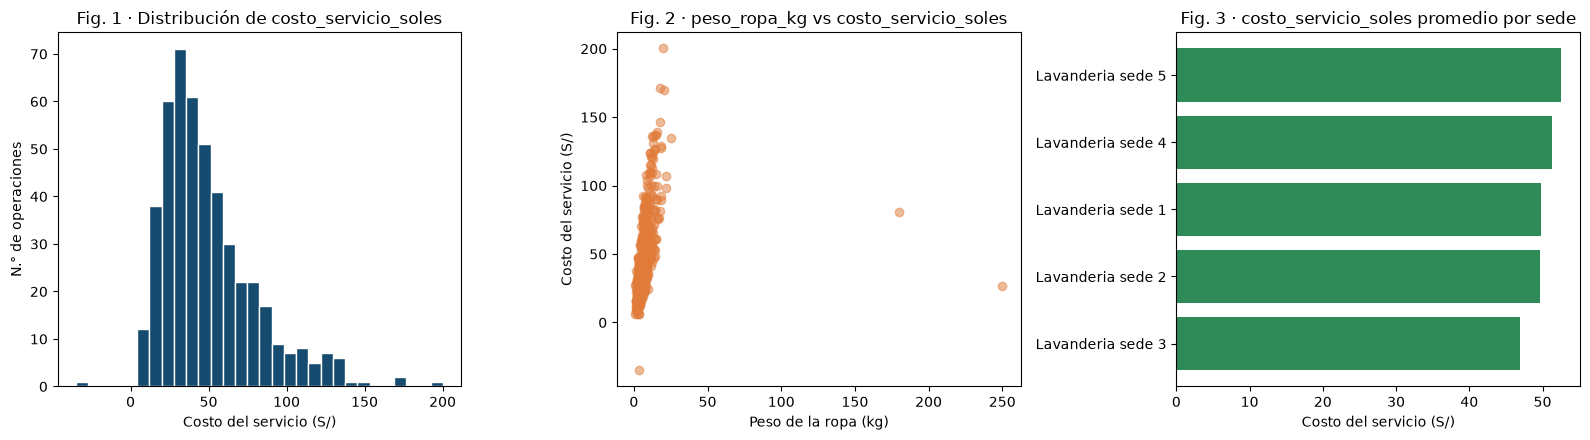

Correlación X-Y (antes de limpiar): 0.209


In [16]:
# Tres gráficos para entender los datos ANTES de limpiar
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (1) Distribución de la variable objetivo: ¿simétrica? ¿cola larga? ¿valores raros?
ax[0].hist(df["costo_servicio_soles"].dropna(), bins=30, color="#164B70", edgecolor="white")
ax[0].set_title("Fig. 1 · Distribución de costo_servicio_soles")
ax[0].set_xlabel("Costo del servicio (S/)"); ax[0].set_ylabel("N.° de operaciones")

# (2) Relación X vs Y: ¿parece una línea? Es la base de la regresión de la sección 7
ax[1].scatter(df["peso_ropa_kg"], df["costo_servicio_soles"], alpha=0.5, color="#E07B39")
ax[1].set_title("Fig. 2 · peso_ropa_kg vs costo_servicio_soles")
ax[1].set_xlabel("Peso de la ropa (kg)"); ax[1].set_ylabel("Costo del servicio (S/)")

# (3) Mirada de negocio: promedio de Y por sede
prom_sede = df.groupby("nombre_sede")["costo_servicio_soles"].mean().sort_values()
ax[2].barh(prom_sede.index, prom_sede.values, color="#2E8B57")
ax[2].set_title("Fig. 3 · costo_servicio_soles promedio por sede")
ax[2].set_xlabel("Costo del servicio (S/)")
plt.tight_layout(); plt.show()

# Correlación de Pearson entre X e Y (solo filas con ambos datos)
print("Correlación X-Y (antes de limpiar):", round(df["peso_ropa_kg"].corr(df["costo_servicio_soles"]), 3))

**Interpretación de los gráficos.**
- *Fig. 1:* la mayoría de pedidos cuesta entre S/ 29 y S/ 64; hay valores aislados por encima de S/ 150 y uno negativo.
- *Fig. 2:* la nube queda "aplastada" porque dos pedidos dicen pesar **180 y 250 kg** (imposible para una lavandería). Por eso la correlación es solo 0.21 antes de limpiar.
- *Fig. 3:* los promedios por local son parecidos (S/ 47 a S/ 52).
- `describe()` lo confirma: el peso máximo es 250 kg cuando el 75 % de los pedidos pesa menos de 8.8 kg.

## 6. Diagnóstico y limpieza de datos (Semana 6)
Regla de trabajo: **primero medir, luego decidir, después comparar**. Ningún registro se elimina sin decir cuántos y por qué.

In [17]:
# ---------- DIAGNÓSTICO: cuantificamos cada problema antes de tocar nada ----------
antes = df.copy()   # guardamos una copia para comparar antes vs después

fecha_txt = antes["fecha"].astype(str).str.strip()
iso = fecha_txt.str.match(r"^\d{4}-\d{2}-\d{2}$")          # formato AAAA-MM-DD

clientes_dim = pd.read_sql_query("SELECT * FROM clientes", conn)
diagnostico = pd.DataFrame({
    "problema": ["Nulos (todas las columnas)", "Filas duplicadas exactas", "Fechas en otro formato (D/M/AAAA)",
                 "Nombres de cliente con espacios extra (tabla clientes)", "Operaciones sin catálogo (FK huérfana)",
                 "Fuera de rango válido (peso 0.5–40 kg, costo > 0)", "Ocupación fuera de 0–100 %"],
    "cantidad": [int(antes.isna().sum().sum()), int(antes.duplicated().sum()), int((~iso).sum()),
                 int((clientes_dim.nombre_cliente != clientes_dim.nombre_cliente.str.strip()).sum()),
                 int(antes["nivel"].isna().sum()),
                 int(((antes['peso_ropa_kg']<0.5)|(antes['peso_ropa_kg']>40)|(antes['costo_servicio_soles']<=0)).sum()),
                 int(((antes['ocupacion_local_pct']<0)|(antes['ocupacion_local_pct']>100)).sum())]
})
print("Nulos por columna:"); print(antes.isna().sum()[antes.isna().sum() > 0], "\n")
diagnostico

Nulos por columna:
nombre_item                2
nivel                      2
precio_referencia_soles    2
peso_ropa_kg               4
prendas_delicadas          5
ocupacion_local_pct        2
costo_servicio_soles       3
dtype: int64 



,problema,cantidad
0,Nulos (todas las columnas),20
1,Filas duplicadas exactas,6
2,Fechas en otro formato (D/M/AAAA),23
3,Nombres de cliente con espacios extra (tabla c...,6
4,Operaciones sin catálogo (FK huérfana),2
5,"Fuera de rango válido (peso 0.5–40 kg, costo > 0)",3
6,Ocupación fuera de 0–100 %,0


peso_ropa_kg: límites IQR [-2.74, 15.76] -> 18 valores fuera; ejemplos: [21.6, 22.0, 25.0, 180.0, 250.0]
costo_servicio_soles: límites IQR [-24.08, 116.64] -> 22 valores fuera; ejemplos: [139.06, 146.3, 170.15, 171.48, 200.22]


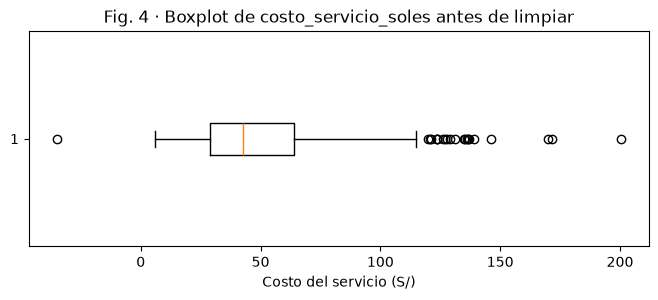

In [18]:
# Extremos con la regla del rango intercuartílico (IQR): solo los SEÑALAMOS, no los borramos automáticamente.
def limites_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["peso_ropa_kg", "costo_servicio_soles"]:
    li, ls = limites_iqr(antes[col].dropna())
    fuera = antes[(antes[col] < li) | (antes[col] > ls)]
    print(f"{col}: límites IQR [{li:.2f}, {ls:.2f}] -> {len(fuera)} valores fuera;",
          "ejemplos:", sorted(fuera[col].round(2).tolist())[-5:])

plt.figure(figsize=(8, 2.8))
plt.boxplot(antes["costo_servicio_soles"].dropna(), vert=False)
plt.title("Fig. 4 · Boxplot de costo_servicio_soles antes de limpiar"); plt.xlabel("Costo del servicio (S/)")
plt.show()

In [19]:
# ---------- LIMPIEZA paso a paso, con bitácora de decisiones ----------
limpio = antes.copy()
bitacora = []   # cada paso registra: qué se hizo, por qué y cuántas filas quedaron
def registrar(paso, motivo):
    bitacora.append({"paso": paso, "motivo": motivo, "filas_resultantes": len(limpio)})

# Paso 1. Duplicados exactos: son la MISMA operación cargada dos veces -> inflarían conteos y promedios
n = len(limpio); limpio = limpio.drop_duplicates()
registrar(f"Eliminar {n - len(limpio)} duplicados exactos", "Misma operación digitada dos veces")

# Paso 2. Fechas: convertimos ambos formatos a tipo fecha. dayfirst porque en Perú se escribe día/mes/año
txt = limpio["fecha"].astype(str).str.strip()
f_iso  = pd.to_datetime(txt, format="%Y-%m-%d", errors="coerce")
f_dmy  = pd.to_datetime(txt, format="%d/%m/%Y", errors="coerce")
limpio["fecha"] = f_iso.fillna(f_dmy)
registrar(f"Unificar fechas (sin convertir: {limpio['fecha'].isna().sum()})", "Había formatos AAAA-MM-DD y D/M/AAAA")

# Paso 3. Textos: quitamos espacios extra y unificamos mayúsculas en las columnas categóricas
for col in ["ciudad", "nivel", "nombre_sede", "zona", "nombre_item"]:
    limpio[col] = limpio[col].astype("string").str.strip().str.lower()
clientes_dim["nombre_cliente"] = clientes_dim["nombre_cliente"].str.strip()   # corregimos también la dimensión
registrar("Quitar espacios y unificar minúsculas en textos", "Evita que 'Lima ' y 'Lima' cuenten como dos ciudades")

# Paso 4. Claves huérfanas: CONSERVAMOS la operación (sus números son válidos) y marcamos la categoría
limpio[["nivel", "nombre_item"]] = limpio[["nivel", "nombre_item"]].fillna("sin catalogo")
limpio["precio_referencia_soles"] = limpio["precio_referencia_soles"].fillna(limpio["precio_referencia_soles"].median())
registrar("Marcar 'sin catalogo' en operaciones con FK huérfana", "La medición es válida; solo falta la descripción del ítem (precio de referencia = mediana)")

# Paso 5. Valores imposibles (fuera de rango válido del negocio): se eliminan porque son errores de registro
n = len(limpio); limpio = limpio[~((limpio['peso_ropa_kg']<0.5)|(limpio['peso_ropa_kg']>40)|(limpio['costo_servicio_soles']<=0))]
registrar(f"Eliminar {n - len(limpio)} valores fuera de rango", "Un pedido de 180 kg o con costo negativo es físicamente imposible: error de digitación")

# Paso 6. Regla lógica del negocio
# La ocupación es un porcentaje: verificamos que esté entre 0 y 100 (si no, sería un error de registro)
k = int(((limpio["ocupacion_local_pct"] < 0) | (limpio["ocupacion_local_pct"] > 100)).sum())
registrar(f"Verificar ocupación 0-100 %: {k} casos fuera de rango", "Se revisó la regla; no requiere cambios si k = 0")

# Paso 7. Nulos en X o en Y: NO se imputan, porque inventar el valor fabricaría la relación que queremos medir
n = len(limpio); limpio = limpio.dropna(subset=["peso_ropa_kg", "costo_servicio_soles"])
registrar(f"Eliminar {n - len(limpio)} filas sin peso_ropa_kg o sin costo_servicio_soles", "Son las variables del modelo; imputarlas sesgaría la regresión")

# Paso 8. Nulos en otras variables numéricas: imputamos con la MEDIANA (robusta a extremos) para conservar la fila
for col in ['prendas_delicadas', 'ocupacion_local_pct']:
    k = limpio[col].isna().sum()
    if k:
        limpio[col] = limpio[col].fillna(limpio[col].median())
        registrar(f"Imputar {k} nulos de {col} con la mediana", "Variable secundaria; se conserva la operación")

# Paso 9. Tipos correctos: los conteos son enteros
for col in ['prendas_delicadas']:
    limpio[col] = limpio[col].round().astype(int)
registrar("Convertir conteos a entero", "Una cantidad de productos/prendas no puede ser 4.5")

pd.DataFrame(bitacora)

,paso,motivo,filas_resultantes
0,Eliminar 6 duplicados exactos,Misma operación digitada dos veces,470
1,Unificar fechas (sin convertir: 0),Había formatos AAAA-MM-DD y D/M/AAAA,470
2,Quitar espacios y unificar minúsculas en textos,Evita que 'Lima ' y 'Lima' cuenten como dos ci...,470
3,Marcar 'sin catalogo' en operaciones con FK hu...,La medición es válida; solo falta la descripci...,470
4,Eliminar 3 valores fuera de rango,Un pedido de 180 kg o con costo negativo es fí...,467
5,Verificar ocupación 0-100 %: 0 casos fuera de ...,Se revisó la regla; no requiere cambios si k = 0,467
6,Eliminar 7 filas sin peso_ropa_kg o sin costo_...,Son las variables del modelo; imputarlas sesga...,460
7,Imputar 5 nulos de prendas_delicadas con la me...,Variable secundaria; se conserva la operación,460
8,Imputar 2 nulos de ocupacion_local_pct con la ...,Variable secundaria; se conserva la operación,460
9,Convertir conteos a entero,Una cantidad de productos/prendas no puede ser...,460


In [20]:
# ---------- ANTES vs DESPUÉS ----------
comparacion = pd.DataFrame({
    "indicador": ["Filas", "Nulos totales", "Duplicados exactos", "Fechas como texto",
                  "Promedio costo_servicio_soles", "Promedio peso_ropa_kg", "Correlación X-Y"],
    "antes": [len(antes), int(antes.isna().sum().sum()), int(antes.duplicated().sum()), "sí",
              round(antes["costo_servicio_soles"].mean(), 2), round(antes["peso_ropa_kg"].mean(), 2), round(antes["peso_ropa_kg"].corr(antes["costo_servicio_soles"]), 3)],
    "despues": [len(limpio), int(limpio.isna().sum().sum()), int(limpio.duplicated().sum()), "no (datetime)",
                round(limpio["costo_servicio_soles"].mean(), 2), round(limpio["peso_ropa_kg"].mean(), 2), round(limpio["peso_ropa_kg"].corr(limpio["costo_servicio_soles"]), 3)],
})
print("Filas conservadas:", f"{len(limpio)/len(antes):.1%}")
display(comparacion)

# Guardamos el resultado en la MISMA base SQLite (la fecha se guarda como texto ISO)
salida = limpio.copy(); salida["fecha"] = salida["fecha"].dt.strftime("%Y-%m-%d")
salida.to_sql("dataset_limpio", conn, if_exists="replace", index=False)
clientes_dim.to_sql("clientes", conn, if_exists="replace", index=False)   # dimensión con nombres corregidos
print(pd.read_sql_query("SELECT COUNT(*) AS filas_dataset_limpio FROM dataset_limpio", conn))

Filas conservadas: 96.6%


,indicador,antes,despues
0,Filas,476,460
1,Nulos totales,20,0
2,Duplicados exactos,6,0
3,Fechas como texto,sí,no (datetime)
4,Promedio costo_servicio_soles,49.86,50.25
5,Promedio peso_ropa_kg,7.87,6.98
6,Correlación X-Y,0.209,0.775


   filas_dataset_limpio
0                   460


**Interpretación y justificación.**
- **Duplicados (6):** misma PK y mismos valores → se eliminan.
- **Fechas (23 en D/M/AAAA):** todas convertidas a fecha.
- **FK huérfana (2 pedidos):** se conservan con la etiqueta "sin catalogo"; su precio de referencia se completa con la mediana del catálogo.
- **Fuera de rango (3 filas):** pedidos de 180 y 250 kg y un costo de S/ -35 se eliminan: son errores de digitación, no clientes reales. **Esta es la decisión que más cambia el análisis:** la correlación peso-costo pasa de 0.21 a 0.78.
- **Nulos en X o Y (7 filas):** se eliminan para no inventar la relación. Los nulos de `prendas_delicadas` (5) y `ocupacion_local_pct` (2) se imputan con la mediana.
- **Extremos plausibles:** costos altos de pedidos de 17 a 20 kg se conservan porque son coherentes con su peso.
- **Resultado:** se conserva el 96.6 % de las filas (460 de 476).

## 7. Regresión lineal simple (Semana 7)
**Pregunta:** ¿Cuántos soles adicionales de costo se asocian a cada kilo adicional de ropa?
- Usamos **una sola** predictora: `peso_ropa_kg`. Es un dato que se conoce **antes** de medir `costo_servicio_soles`, así que no hay *fuga de información* (no usamos el resultado para predecirse a sí mismo).
- Separamos **80 % entrenamiento / 20 % prueba**: el modelo se evalúa con operaciones que nunca vio.

In [21]:
# Leemos desde SQLite la tabla limpia (así demostramos que el flujo SQL -> pandas funciona)
datos = pd.read_sql_query("SELECT id_operacion, peso_ropa_kg, costo_servicio_soles FROM dataset_limpio", conn)
X = datos[["peso_ropa_kg"]]          # doble corchete: scikit-learn espera una tabla (2D) para X
y = datos["costo_servicio_soles"]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, datos["id_operacion"], test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", len(X_train), "filas | Prueba:", len(X_test), "filas")

modelo = LinearRegression().fit(X_train, y_train)   # aprende la recta SOLO con entrenamiento
b0, b1 = modelo.intercept_, modelo.coef_[0]
y_pred = modelo.predict(X_test)                     # predice sobre datos que no vio

r2   = r2_score(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, y_pred)
print(f"Ecuación: costo_servicio_soles = {b0:.2f} + {b1:.2f} x peso_ropa_kg")
print(f"R² prueba = {r2:.3f} | MSE = {mse:.2f} | RMSE = {rmse:.2f} | MAE = {mae:.2f}")
print(f"R² entrenamiento = {modelo.score(X_train, y_train):.3f}  (si fuera mucho mayor que en prueba, habría sobreajuste)")

Entrenamiento: 368 filas | Prueba: 92 filas
Ecuación: costo_servicio_soles = 7.66 + 6.14 x peso_ropa_kg
R² prueba = 0.479 | MSE = 328.87 | RMSE = 18.13 | MAE = 14.39
R² entrenamiento = 0.618  (si fuera mucho mayor que en prueba, habría sobreajuste)


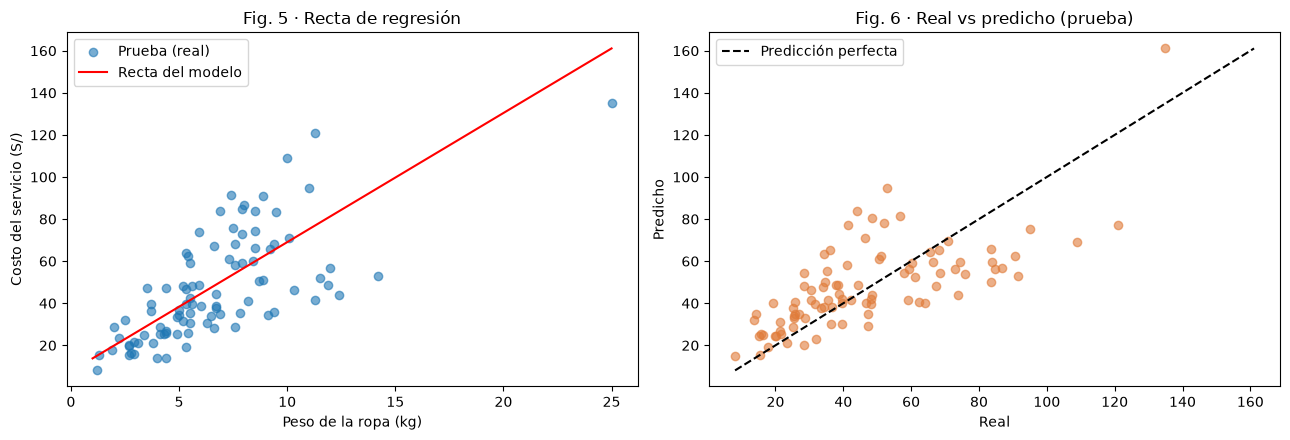

,id_operacion,peso_ropa_kg,costo_servicio_soles_real,costo_servicio_soles_predicho,error
0,O160303,6.6,67.30,48.17,19.13
1,O160389,8.0,86.69,56.76,29.93
2,O160424,6.7,44.41,48.78,-4.37
3,O160384,5.3,46.81,40.19,6.62
4,O160385,8.9,90.73,62.28,28.45


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# Recta ajustada sobre los datos de prueba
xs = np.linspace(X[ "peso_ropa_kg"].min(), X["peso_ropa_kg"].max(), 50)
ax[0].scatter(X_test["peso_ropa_kg"], y_test, alpha=0.6, label="Prueba (real)")
ax[0].plot(xs, b0 + b1 * xs, color="red", label="Recta del modelo")
ax[0].set_title("Fig. 5 · Recta de regresión"); ax[0].set_xlabel("Peso de la ropa (kg)"); ax[0].set_ylabel("Costo del servicio (S/)")
ax[0].legend()
# Real vs predicho: si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal
ax[1].scatter(y_test, y_pred, alpha=0.6, color="#E07B39")
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[1].plot(lim, lim, "k--", label="Predicción perfecta")
ax[1].set_title("Fig. 6 · Real vs predicho (prueba)"); ax[1].set_xlabel("Real"); ax[1].set_ylabel("Predicho")
ax[1].legend(); plt.tight_layout(); plt.show()

# Guardamos reales y predichos en SQLite (lo pide la consigna)
predicciones = pd.DataFrame({"id_operacion": id_test.values, "peso_ropa_kg": X_test["peso_ropa_kg"].values,
                              "costo_servicio_soles_real": y_test.values, "costo_servicio_soles_predicho": y_pred.round(2)})
predicciones["error"] = (predicciones["costo_servicio_soles_real"] - predicciones["costo_servicio_soles_predicho"]).round(2)
predicciones.to_sql("predicciones_regresion", conn, if_exists="replace", index=False)
predicciones.head()

In [23]:
# Uso del modelo en consola: la gerencia escribe un valor de peso_ropa_kg y obtiene la estimación.
# (Si el notebook se ejecuta automáticamente sin teclado, se usa un valor de ejemplo.)
def estimar(valor_x):
    return b0 + b1 * valor_x

try:
    valor = float(input("Ingrese Peso de la ropa (kg): "))
except Exception:
    valor = 8
    print("Sin entrada de teclado; se usa el ejemplo:", valor)
print(f"Para peso_ropa_kg = {valor}, el modelo estima costo_servicio_soles ≈ {estimar(valor):.2f} (soles),",
      f"con un error típico de ± {rmse:.2f}")

Sin entrada de teclado; se usa el ejemplo: 8
Para peso_ropa_kg = 8, el modelo estima costo_servicio_soles ≈ 56.76 (soles), con un error típico de ± 18.13


**Interpretación.**
- **Pendiente (β₁ = 6.14):** en promedio, **cada kilo adicional de ropa se asocia con S/ 6.14 más de costo**. Es una referencia útil para unificar la tarifa entre locales.
- **Intercepto (β₀ = 7.66):** es un cargo base del modelo; no se cobra por 0 kg, así que no se interpreta literalmente.
- **R² = 0.479 (prueba):** el peso explica cerca del **48 %** de la variación del costo. El resto depende del tipo de servicio (al seco cuesta más), de las prendas delicadas, etc.
- **RMSE = S/ 18.13 / MAE = S/ 14.39:** el error típico es alto respecto al costo medio (S/ 50): sirve como **tarifa de referencia**, no para cotizar cada pedido.
- R² de entrenamiento (0.618) es mayor que el de prueba (0.479). Con una sola variable no es un sobreajuste por complejidad: la muestra de prueba (92 pedidos) contiene más pedidos *especiales* que no siguen la tarifa por kilo. Es un límite que hay que reconocer.
- **Límites:** asociación, no causalidad; datos sintéticos; validado solo entre 1 y 25 kg.

## 8. Segmentación con K-Means (clustering)
- **¿Qué representa cada fila?** Cada fila de `operaciones` es **un pedido de lavado**.
- **Variables:** `peso_ropa_kg`, `prendas_delicadas`, `ocupacion_local_pct`, `costo_servicio_soles`. Son numéricas y describen el tipo de operación.
- **Escalado:** las variables tienen unidades distintas; sin `StandardScaler`, la de números más grandes dominaría la distancia.

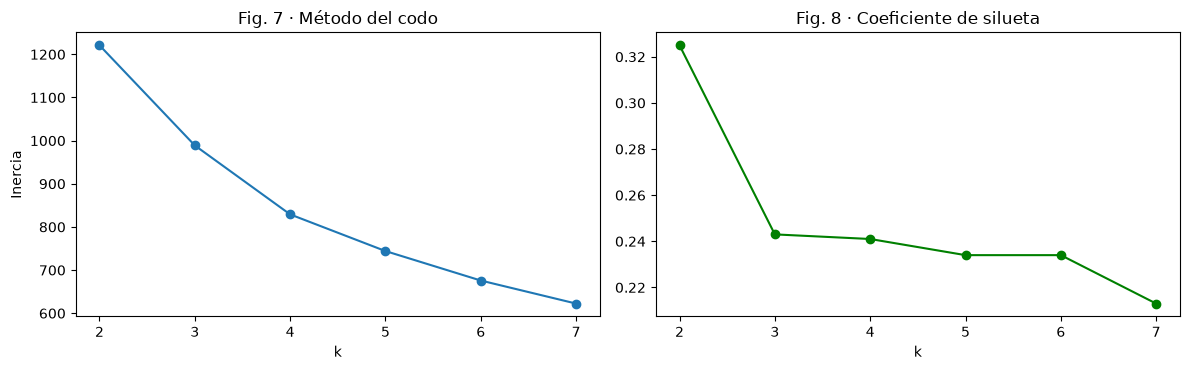

,k,inercia,silueta
0,2,1221.0,0.325
1,3,988.9,0.243
2,4,829.1,0.241
3,5,744.1,0.234
4,6,675.8,0.234
5,7,622.4,0.213


In [24]:
VARS_K = ['peso_ropa_kg', 'prendas_delicadas', 'ocupacion_local_pct', 'costo_servicio_soles']
seg = pd.read_sql_query(f"SELECT id_operacion, {', '.join(VARS_K)} FROM dataset_limpio", conn)
Z = StandardScaler().fit_transform(seg[VARS_K])       # media 0, desviación 1 en cada variable

# Probamos k = 2..7 y medimos inercia (método del codo) y silueta (qué tan separados quedan los grupos)
pruebas = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    pruebas.append({"k": k, "inercia": round(km.inertia_, 1), "silueta": round(silhouette_score(Z, km.labels_), 3)})
pruebas = pd.DataFrame(pruebas)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(pruebas.k, pruebas.inercia, "o-"); ax[0].set_title("Fig. 7 · Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(pruebas.k, pruebas.silueta, "o-", color="green"); ax[1].set_title("Fig. 8 · Coeficiente de silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pruebas

In [25]:
K = 3   # elegido con el codo + silueta (ver interpretación abajo)
km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z)
seg["segmento"] = km.labels_

# Perfil de cada segmento en las unidades ORIGINALES (no escaladas), para poder leerlo en lenguaje de negocio
perfil = seg.groupby("segmento")[VARS_K].mean().round(2)
perfil["operaciones"] = seg["segmento"].value_counts().sort_index()
perfil["% del total"] = (perfil["operaciones"] / len(seg) * 100).round(1)
perfil

,peso_ropa_kg,prendas_delicadas,ocupacion_local_pct,costo_servicio_soles,operaciones,% del total
segmento,,,,,,
0,5.34,1.79,36.51,34.92,155,33.7
1,5.27,1.43,69.44,38.41,181,39.3
2,11.52,3.48,54.73,86.69,124,27.0


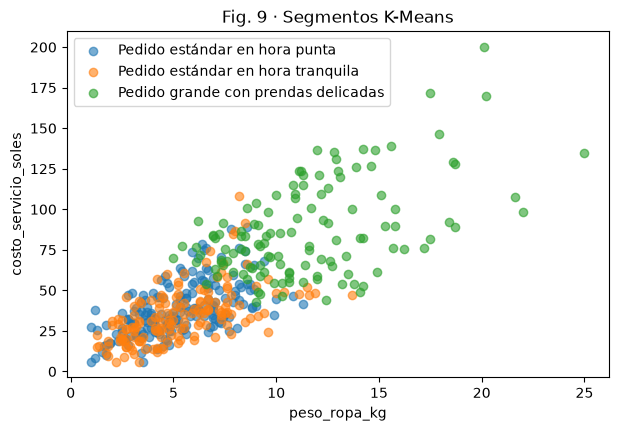

nombre_segmento
Pedido estándar en hora punta          181
Pedido estándar en hora tranquila      155
Pedido grande con prendas delicadas    124
Name: count, dtype: int64


In [26]:
# Nombres de negocio para cada segmento (los decide el equipo mirando el perfil de la celda anterior)
nombres = {0: 'Pedido estándar en hora tranquila', 1: 'Pedido estándar en hora punta', 2: 'Pedido grande con prendas delicadas'}
seg["nombre_segmento"] = seg["segmento"].map(nombres)
seg.to_sql("segmentos_kmeans", conn, if_exists="replace", index=False)   # asignación guardada en SQLite

plt.figure(figsize=(7, 4.5))
for s, g in seg.groupby("nombre_segmento"):
    plt.scatter(g["peso_ropa_kg"], g["costo_servicio_soles"], alpha=0.6, label=s)
plt.xlabel("peso_ropa_kg"); plt.ylabel("costo_servicio_soles")
plt.title("Fig. 9 · Segmentos K-Means"); plt.legend(); plt.show()
print(seg["nombre_segmento"].value_counts())

**Elección de k.** La silueta es mayor en k = 2 (0.325), pero esa partición solo separa pedidos grandes de pequeños. En k = 3 la inercia sigue bajando de forma marcada (1221 → 989) y la silueta (0.243) es similar a la de k = 4–6; además aparece un grupo útil: los pedidos pequeños **en hora punta**. Elegimos **k = 3**.

| Segmento | Perfil promedio | % pedidos | Acción sugerida |
|---|---|---|---|
| Pedido estándar en hora tranquila | 5.3 kg, 1.8 delicadas, ocupación 37 %, **S/ 34.9** | 33.7 % | Promociones para atraer pedidos en estas horas |
| Pedido estándar en hora punta | 5.3 kg, 1.4 delicadas, ocupación 69 %, **S/ 38.4** | 39.3 % | Mover parte de estos pedidos a horas tranquilas (descuento por horario) |
| Pedido grande con prendas delicadas | 11.5 kg, 3.5 delicadas, ocupación 55 %, **S/ 86.7** | 27.0 % | Atención prioritaria y personal capacitado en prendas delicadas |

Silueta de 0.24: los grupos se **superponen** bastante; son orientativos.

## 9. Cifras clave (para que el informe coincida con el Colab) y tablas creadas

In [27]:
# Este resumen evita errores al copiar cifras al informe: todo sale de las variables calculadas arriba
resumen = {
    "filas_originales": len(antes), "filas_limpias": len(limpio),
    "duplicados": int(antes.duplicated().sum()), "nulos_originales": int(antes.isna().sum().sum()),
    "intercepto_b0": round(b0, 3), "pendiente_b1": round(b1, 3),
    "r2_prueba": round(r2, 3), "mse": round(mse, 2), "rmse": round(rmse, 2), "mae": round(mae, 2),
    "n_train": len(X_train), "n_test": len(X_test), "k_elegido": K,
}
for k_, v_ in resumen.items():
    print(f"{k_:18s}: {v_}")
print("\nTablas y vistas en la base:")
print(pd.read_sql_query("SELECT type, name FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name", conn))

filas_originales  : 476
filas_limpias     : 460
duplicados        : 6
nulos_originales  : 20
intercepto_b0     : 7.662
pendiente_b1      : 6.137
r2_prueba         : 0.479
mse               : 328.87
rmse              : 18.13
mae               : 14.39
n_train           : 368
n_test            : 92
k_elegido         : 3

Tablas y vistas en la base:
    type                    name
0  table                catalogo
1  table                clientes
2  table          dataset_limpio
3  table             operaciones
4  table  predicciones_regresion
5  table                   sedes
6  table        segmentos_kmeans
7   view            vw_analitica


## 10. Conclusiones y recomendación (con palabras del equipo)
1. **Integración:** se detectaron 6 duplicados y 2 pedidos con un servicio inexistente; el LEFT JOIN permitió conservarlos.
2. **Calidad:** eliminar 3 valores imposibles cambió la correlación peso-costo de 0.21 a 0.78: sin limpieza, la conclusión habría sido errónea.
3. **Regresión:** cada kilo adicional se asocia con ~S/ 6.1 más (R² = 0.48; error típico ≈ S/ 18).
4. **Segmentos:** el 39.3 % de los pedidos son pequeños pero llegan en hora punta.

**Recomendación:** usar S/ 6.1 por kg como **tarifa de referencia común** para los cinco locales (más un recargo para servicios especiales) y ofrecer un descuento a los pedidos estándar que se dejen en horas de baja ocupación. Antes de aplicarlo, validar con datos reales, porque los datos del caso son sintéticos y la regresión no prueba causalidad.